In [1]:
# !pip install -q kaggle
# !kaggle --version

# !kaggle datasets download dinmkeljiame/doctamper
# !mkdir input && mkdir input/datasets
# !mv doctamper.zip input/datasets
# !unzip -o input/datasets/doctamper.zip -d input/datasets/

# Block 1: Global Config & Reproducibility

In [2]:
from pathlib import Path

import random
from random import sample
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

!pip install lmdb
import lmdb
from PIL import Image
from io import BytesIO
from tqdm import tqdm

from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import mobilenet_v3_large, MobileNet_V3_Large_Weights
from torchvision.models import resnet18, ResNet18_Weights
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights


DATA_PATH = Path("/workspace/input/datasets")
BEST_MODEL_PATH = Path("/workspace/working/checkpoints/best_model.pth")
BEST_MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

SEED = 1337
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)


TEST_SIZE = 0.1
NUM_WORKERS = 0
BATCH_SIZE = 4

EPOCHS = 20
ENCODER_LR = 5e-4
DECODER_LR = 5e-3
WD = 1e-4

TRAIN_MVP = 3000
VAL_MVP = TRAIN_MVP//4

cuda


In [3]:
for data_group in DATA_PATH.iterdir():
    print(data_group)

/workspace/input/datasets/DocTamperV1-TestingSet
/workspace/input/datasets/DocTamperV1-TrainingSet
/workspace/input/datasets/DocTamperV1-SCD
/workspace/input/datasets/DocTamperV1-FCD


# Block 2: Data Discorvering & Data Prepreration

In [4]:
envs = {
    data_group.parts[-1]: lmdb.open(
        str(data_group),
        readonly=True,
        lock=True,
        readahead=False,
        meminit=False,
        max_readers=512
    )
    for data_group in DATA_PATH.iterdir()
}
print(envs)

{'DocTamperV1-TestingSet': <Environment object at 0x7ddcbc608730>, 'DocTamperV1-TrainingSet': <Environment object at 0x7ddcbc608830>, 'DocTamperV1-SCD': <Environment object at 0x7ddcbc608630>, 'DocTamperV1-FCD': <Environment object at 0x7ddcbc608930>}


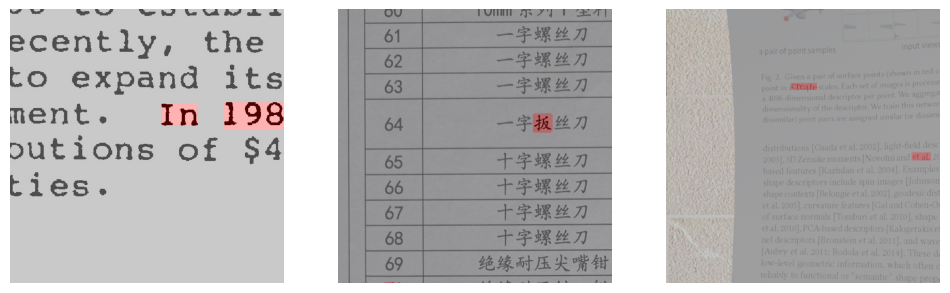

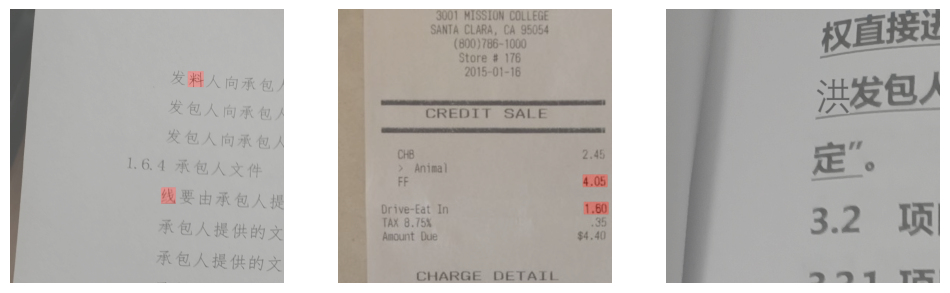

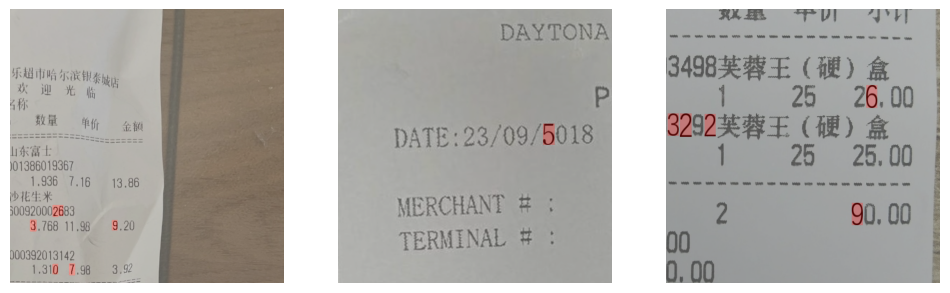

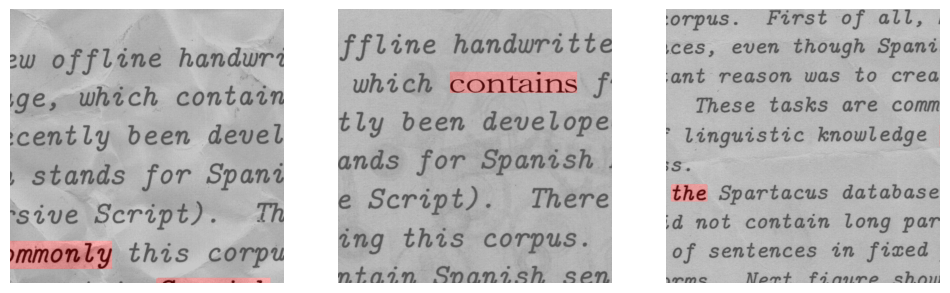

In [5]:
def get_masked_image(env, idx) -> Image.Image:
    with env.begin() as txn:
        image_buffer = txn.get(("image-%09d" % idx).encode("utf-8"))
        label_buffer = txn.get(("label-%09d" % idx).encode("utf-8"))

    image = Image.open(BytesIO(image_buffer)).convert("RGBA")
    label = Image.open(BytesIO(label_buffer))
    
    mask = np.array(label)

    tmp = np.tile([0, 0, 0, 0], (*mask.shape, 1)).astype(np.uint8)
    tmp[mask == 255] = [255, 0, 0, 255]
    mask = Image.fromarray(tmp)
    
    del tmp
    
    return Image.blend(im1=image, im2=mask, alpha=0.3)

def display_images(images: list[Image.Image]):
    fig, axes = plt.subplots(1, len(images), figsize=(len(images)*4, 6))

    for ax, img in zip(axes, images):
        ax.imshow(img)
        ax.axis("off")

    plt.show()

display_images([get_masked_image(envs["DocTamperV1-TrainingSet"], i) for i in sample(population=range(0,200), k=3)])
display_images([get_masked_image(envs["DocTamperV1-TestingSet"], i) for i in sample(population=range(0,200), k=3)])
display_images([get_masked_image(envs["DocTamperV1-SCD"], i) for i in sample(population=range(0,200), k=3)])
display_images([get_masked_image(envs["DocTamperV1-FCD"], i) for i in sample(population=range(0,200), k=3)])

# Block 3: Validation Strategy & Data Augmentation

In [6]:
def get_num_samples(env):
    with env.begin() as txn:
        value = txn.get(b"num-samples")

    return int(value.decode("utf-8"))


train_env = envs["DocTamperV1-TrainingSet"]


n_train = get_num_samples(train_env)


all_train_indices = np.arange(n_train)


train_indices, val_indices = train_test_split(all_train_indices, test_size=TEST_SIZE, random_state=SEED, shuffle=True)

# This is for MVP
train_indices = train_indices[:TRAIN_MVP]
val_indices = val_indices[:VAL_MVP]

print(f"Train samples: {len(train_indices):,}")
print(f"Validation samples: {len(val_indices):,}")


Train samples: 3,000
Validation samples: 750


In [7]:
image_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

mask_transform = transforms.Compose([
    transforms.ToTensor(),
])

# Block 4: Dataset & Data Loader

In [8]:
class DocTamperDataset(Dataset):
    def __init__(self, env, indices, image_transform, mask_transform):
        self.env = env
        self.indices = indices
        self.image_transform = image_transform
        self.mask_transform = mask_transform 

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        sample_idx = int(self.indices[index])

        image_key = f"image-{sample_idx:09d}".encode("utf-8")
        label_key = f"label-{sample_idx:09d}".encode("utf-8")

        with self.env.begin() as txn:
            image_buffer = txn.get(image_key)
            label_buffer = txn.get(label_key)

        image = Image.open(BytesIO(image_buffer)).convert("RGB")
        mask = Image.open(BytesIO(label_buffer)).convert("L")

        image_tensor = self.image_transform(image)
        mask_tensor = (self.mask_transform(mask) > 0.5).float()

        return image_tensor, mask_tensor

train_dataset = DocTamperDataset(train_env, train_indices, image_transform, mask_transform)
val_dataset = DocTamperDataset(train_env, val_indices, image_transform, mask_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=(device == "cuda"), persistent_workers=(NUM_WORKERS > 0))
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=(device == "cuda"), persistent_workers=(NUM_WORKERS > 0))

# Block 5: Modeling & Hyperparameter

In [10]:
class DepthwiseSeparableBlock(nn.Module):
    """Lightweight pointwise + depthwise + pointwise convolution block."""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels, out_channels,
                kernel_size=3, padding=1,
                groups=out_channels, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class SCSEModule(nn.Module):
    """Concurrent channel and spatial squeeze-excitation."""
    def __init__(self, channels, reduction=8):
        super().__init__()
        hidden = max(channels // reduction, 4)

        self.channel_attention = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(channels, hidden, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, channels, kernel_size=1),
            nn.Sigmoid(),
        )

        self.spatial_attention = nn.Sequential(
            nn.Conv2d(channels, 1, kernel_size=1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        channel_features = x * self.channel_attention(x)
        spatial_features = x * self.spatial_attention(x)
        return channel_features + spatial_features


In [11]:
class BlockDCT(nn.Module):
    """Orthonormal 8x8 block DCT; output: [B, 64, H/8, W/8]."""
    def __init__(self, block_size=8, mean=MEAN, std=STD):
        super().__init__()
        self.block_size = block_size
        self.register_buffer("mean", torch.tensor(mean).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(std).view(1, 3, 1, 1))

        # Build the orthonormal DCT-II basis.
        n = block_size
        basis = torch.empty(n, n, dtype=torch.float32)
        for u in range(n):
            alpha = (1.0 / n) ** 0.5 if u == 0 else (2.0 / n) ** 0.5
            for pos in range(n):
                basis[u, pos] = alpha * torch.cos(
                    torch.tensor((2 * pos + 1) * u * torch.pi / (2 * n))
                )
        self.register_buffer("basis", basis)

    def forward(self, image):
        # The input image is ImageNet-normalized. Recover RGB in [0, 1].
        # Run fixed DCT operations in FP32 for numerical stability under AMP.
        with torch.autocast(device_type=image.device.type, enabled=False):
            image = image.float() * self.std + self.mean
            image = image.clamp(0.0, 1.0)

            gray = (
                0.299 * image[:, 0:1]
                + 0.587 * image[:, 1:2]
                + 0.114 * image[:, 2:3]
            )

            batch_size, _, height, width = gray.shape
            n = self.block_size
            pad_h = (n - height % n) % n
            pad_w = (n - width % n) % n

            if pad_h or pad_w:
                gray = F.pad(gray, (0, pad_w, 0, pad_h), mode="replicate")

            # Non-overlapping 8x8 blocks.
            patches = F.unfold(gray, kernel_size=n, stride=n)
            grid_h = gray.shape[-2] // n
            grid_w = gray.shape[-1] // n
            patches = patches.transpose(1, 2).reshape(
                batch_size, grid_h * grid_w, n, n
            )

            basis = self.basis.to(device=image.device, dtype=torch.float32)
            coeff = torch.matmul(basis, patches)
            coeff = torch.matmul(coeff, basis.t())

            # [B, number_of_blocks, 8, 8] -> [B, 64, grid_h, grid_w]
            coeff = coeff.reshape(batch_size, grid_h, grid_w, n, n)
            coeff = coeff.permute(0, 3, 4, 1, 2).contiguous()
            coeff = coeff.reshape(batch_size, n * n, grid_h, grid_w)

            # Signed log compression of coefficient range.
            coeff = torch.sign(coeff) * torch.log1p(torch.abs(coeff) * 8.0)

        return coeff


class LightweightFrequencyHead(nn.Module):
    """Small DCT feature encoder; original JPEG QT embedding is omitted."""
    def __init__(self, out_channels=32):
        super().__init__()
        self.block_dct = BlockDCT(block_size=8)

        self.projection = nn.Sequential(
            nn.Conv2d(64, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )
        self.refine = DepthwiseSeparableBlock(out_channels, out_channels)

    def forward(self, image):
        dct_map = self.block_dct(image)
        features = self.projection(dct_map)
        return self.refine(features)


In [12]:
class LiteMID(nn.Module):
    """
    Lightweight approximation of DTD's Multi-view Iterative Decoder.

    Inputs are ordered from high to low spatial resolution:
      f0: [B, 24,   H/4,  W/4]
      f1: [B, 40,   H/8,  W/8]   (already fused with DCT features)
      f2: [B, 112,  H/16, W/16]
      f3: [B, 1280, H/32, W/32]

    The decoder builds a small nested decoding grid:
      first view:  x00, x11, x22
      second view: x01, x12
      final view:  x02

    This preserves the iterative multi-scale aggregation idea while
    using depthwise-separable convolutions to reduce compute.
    """
    def __init__(self, in_channels=(24, 40, 112, 1280), width=48):
        super().__init__()

        self.projections = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(ch, width, kernel_size=1, bias=False),
                nn.BatchNorm2d(width),
                nn.ReLU(inplace=True),
            )
            for ch in in_channels
        ])

        # View 1: adjacent-scale decoding.
        self.x00 = DepthwiseSeparableBlock(width * 2, width)
        self.x11 = DepthwiseSeparableBlock(width * 2, width)
        self.x22 = DepthwiseSeparableBlock(width * 2, width)

        # View 2: aggregate the previous view and encoder skip features.
        self.x01 = DepthwiseSeparableBlock(width * 3, width)
        self.x12 = DepthwiseSeparableBlock(width * 3, width)

        # View 3: final iterative aggregation at H/4.
        self.x02 = DepthwiseSeparableBlock(width * 4, width)

        self.refine = SCSEModule(width)

    @staticmethod
    def upsample_to(x, reference):
        return F.interpolate(
            x,
            size=reference.shape[-2:],
            mode="bilinear",
            align_corners=False,
        )

    def forward(self, f0, f1, f2, f3):
        # Project all encoder scales to a compact common channel width.
        p0, p1, p2, p3 = [
            projection(feature)
            for projection, feature in zip(
                self.projections, (f0, f1, f2, f3)
            )
        ]

        # View 1: coarse-to-fine decoding on adjacent scales.
        x00 = self.x00(torch.cat([
            self.upsample_to(p3, p2), p2
        ], dim=1))

        x11 = self.x11(torch.cat([
            self.upsample_to(p2, p1), p1
        ], dim=1))

        x22 = self.x22(torch.cat([
            self.upsample_to(p1, p0), p0
        ], dim=1))

        # View 2: iterative fusion of decoder outputs and encoder features.
        x01 = self.x01(torch.cat([
            self.upsample_to(x00, x11),
            x11,
            p1,
        ], dim=1))

        x12 = self.x12(torch.cat([
            self.upsample_to(x11, x22),
            x22,
            p0,
        ], dim=1))

        # View 3: final multi-view aggregation at 1/4 resolution.
        x02 = self.x02(torch.cat([
            self.upsample_to(x01, x22),
            x12,
            x22,
            p0,
        ], dim=1))

        return self.refine(x02)


class LightweightDTD(nn.Module):
    """
    DTD-inspired lightweight model:
      - Spatial branch: EfficientNet-B0
      - Frequency branch: block-wise 8x8 DCT
      - Fusion: scSE + 1x1 projection at 1/8 resolution
      - Decoder: LiteMID (nested multi-view iterative decoder)

    This is not a reproduction of the original DTD MID. It is a
    compute-conscious approximation of its multi-view iterative idea.
    """
    def __init__(
        self,
        pretrained=True,
        out_channels=1,
        frequency_channels=32,
        decoder_width=48,
    ):
        super().__init__()

        weights = EfficientNet_B0_Weights.DEFAULT if pretrained else None
        backbone = efficientnet_b0(weights=weights)
        self.encoder = backbone.features

        self.frequency_branch = LightweightFrequencyHead(
            out_channels=frequency_channels
        )

        self.frequency_fusion = nn.Sequential(
            SCSEModule(40 + frequency_channels),
            nn.Conv2d(
                40 + frequency_channels,
                40,
                kernel_size=1,
                bias=False,
            ),
            nn.BatchNorm2d(40),
            nn.ReLU(inplace=True),
        )

        self.decoder = LiteMID(
            in_channels=(24, 40, 112, 1280),
            width=decoder_width,
        )

        self.segmentation_head = nn.Conv2d(
            decoder_width,
            out_channels,
            kernel_size=1,
        )

    def forward(self, x):
        input_size = x.shape[-2:]

        # EfficientNet-B0 feature taps:
        # features[2]: 24 channels, stride 4
        # features[3]: 40 channels, stride 8
        # features[5]: 112 channels, stride 16
        # features[8]: 1280 channels, stride 32
        z = x
        f0 = f1 = f2 = f3 = None

        for idx, layer in enumerate(self.encoder):
            z = layer(z)

            if idx == 2:
                f0 = z
            elif idx == 3:
                f1 = z
            elif idx == 5:
                f2 = z
            elif idx == 8:
                f3 = z

        # DCT frequency features are fused at the 1/8 scale.
        freq = self.frequency_branch(x)

        if freq.shape[-2:] != f1.shape[-2:]:
            freq = F.interpolate(
                freq,
                size=f1.shape[-2:],
                mode="bilinear",
                align_corners=False,
            )

        f1 = self.frequency_fusion(
            torch.cat([f1, freq], dim=1)
        )

        # Four-scale iterative decoder.
        decoded = self.decoder(f0, f1, f2, f3)

        logits = self.segmentation_head(decoded)

        return F.interpolate(
            logits,
            size=input_size,
            mode="bilinear",
            align_corners=False,
        )


model = LightweightDTD(
    pretrained=True,
    out_channels=1,
    frequency_channels=32,
    decoder_width=48,
).to(device)

In [13]:
model.eval()

with torch.no_grad():
    dummy = torch.randn(2, 3, 224, 224).to(device)
    output = model(dummy)

print("Input:", dummy.shape)
print("Output:", output.shape)
print("Total parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
print("Trainable parameters:", f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

assert output.shape == (2, 1, 224, 224)


Input: torch.Size([2, 3, 224, 224])
Output: torch.Size([2, 1, 224, 224])
Total parameters: 4,142,606
Trainable parameters: 4,142,606


In [14]:
class BCEDiceLoss(nn.Module):
    def __init__(self, dice_weight=1.0, smooth=1.0):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.dice_weight = dice_weight
        self.smooth = smooth

    def forward(self, logits, targets):
        logits = logits.float()  # compute the loss in fp32 even under autocast
        bce = self.bce(logits, targets)
        probs = torch.sigmoid(logits)
        inter = (probs * targets).sum()
        dice = (2.0 * inter + self.smooth) / (probs.sum() + targets.sum() + self.smooth)
        return bce + self.dice_weight * (1.0 - dice)

criterion = BCEDiceLoss()

encoder_params = list(model.encoder.parameters())
decoder_params = [
    param
    for name, param in model.named_parameters()
    if not name.startswith("encoder.")
]
optimizer = torch.optim.AdamW([
    {"params": encoder_params, "lr": ENCODER_LR},
    {"params": decoder_params, "lr": DECODER_LR},
], weight_decay=WD)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))

# Block 6: Training & Validation Loop

In [15]:
def calculate_batch_dice(logits, masks, threshold=0.5, smooth=1e-6):
    predictions = (torch.sigmoid(logits) >= threshold).float()
    targets = (masks >= 0.5).float()

    predictions = predictions.flatten(start_dim=1)
    targets = targets.flatten(start_dim=1)

    intersection = (predictions * targets).sum(dim=1)
    pred_sum = predictions.sum(dim=1)
    target_sum = targets.sum(dim=1)

    dice = (2.0 * intersection + smooth) / (
        pred_sum + target_sum + smooth
    )

    return dice.sum().item(), dice.numel()


In [16]:
@torch.no_grad()
def validate_one_epoch(model, loader, criterion):
    model.eval()

    running_loss = 0.0
    total_dice = 0.0
    total_images = 0

    progress_bar = tqdm(loader, desc="Validation")

    for images, masks in progress_bar:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        with torch.autocast(device_type=device, dtype=torch.float16, enabled=(device == "cuda")):
            logits = model(images)
            loss = criterion(logits, masks)

        batch_size = images.size(0)
        batch_dice_sum, num_images = calculate_batch_dice(logits, masks)

        running_loss += loss.item() * batch_size
        total_dice += batch_dice_sum
        total_images += num_images

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}",
            macro_dice=f"{batch_dice_sum / num_images:.4f}"
        )

    avg_loss = running_loss / len(loader.dataset)
    avg_macro_dice = total_dice / total_images

    return avg_loss, avg_macro_dice


In [17]:
def train_one_epoch(model, loader, criterion, optimizer, scaler):
    model.train()
    running_loss = 0.0

    progress_bar = tqdm(loader, desc="Train")

    for images, masks in progress_bar:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type=device, dtype=torch.float16, enabled=(device == "cuda")):
            logits = model(images)
            loss = criterion(logits, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = images.size(0)
        running_loss += loss.item() * batch_size

        progress_bar.set_postfix(loss=f"{loss.item():.4f}")

    return running_loss / len(loader.dataset)

In [18]:
best_val_dice = -1.0
for epoch in range(EPOCHS):
    print("epoch: ", epoch)
    
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, scaler)
    print("train_loss: ", train_loss)

    val_loss, val_dice = validate_one_epoch(model, val_loader, criterion)
    print("val_loss: ", val_loss)
    print("val_dice: ", val_dice)
    
    scheduler.step()

    if val_dice > best_val_dice:
        best_val_dice = val_dice
        torch.save({
            "epoch": epoch+1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "best_val_dice": best_val_dice,
        }, BEST_MODEL_PATH)
        print(f"Saved new best model (Val dice: {best_val_dice:.4f})")


print(f"Training completed. Best Val Dice: {best_val_dice:.4f}")

epoch:  0


Train: 100%|██████████| 750/750 [00:55<00:00, 13.50it/s, loss=1.0138]


train_loss:  0.8944632438421249


Validation: 100%|██████████| 188/188 [00:27<00:00,  6.87it/s, loss=0.5560, macro_dice=0.3489]


val_loss:  0.7479813704490662
val_dice:  0.31438645824538025
Saved new best model (Val dice: 0.3144)
epoch:  1


Train: 100%|██████████| 750/750 [00:55<00:00, 13.49it/s, loss=0.3866]


... (71 outputs left out)

Train: 100%|██████████| 750/750 [00:53<00:00, 14.09it/s, loss=0.4180]


train_loss:  0.25399317319691184


Validation: 100%|██████████| 188/188 [00:25<00:00,  7.44it/s, loss=0.1974, macro_dice=0.7542]

val_loss:  0.3314249575336774
val_dice:  0.6566650313635667
Training completed. Best Val Dice: 0.6658


# Block 7: Inference

In [19]:
checkpoint = torch.load(BEST_MODEL_PATH, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])

model.eval();

In [20]:
@torch.no_grad()
def evaluate(model, loader, device, threshold=0.5, dataset_name="Test"):
    model.eval()

    # Global pixel counts for Micro metrics
    tp = 0
    fp = 0
    fn = 0
    tn = 0

    # Per-image Dice aggregation for Macro Dice
    total_dice = 0.0
    total_images = 0

    progress_bar = tqdm(loader, desc=f"Evaluating {dataset_name}")

    for images, masks in progress_bar:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        with torch.autocast(
            device_type=device,
            dtype=torch.float16,
            enabled=(device == "cuda")
        ):
            logits = model(images)

        predictions = (torch.sigmoid(logits) >= threshold).to(torch.uint8)
        targets = (masks >= 0.5).to(torch.uint8)

        # Micro metrics: aggregate pixels across the whole dataset.
        tp += ((predictions == 1) & (targets == 1)).sum().item()
        fp += ((predictions == 1) & (targets == 0)).sum().item()
        fn += ((predictions == 0) & (targets == 1)).sum().item()
        tn += ((predictions == 0) & (targets == 0)).sum().item()

        # Macro Dice: calculate one Dice score per image.
        batch_dice_sum, num_images = calculate_batch_dice(
            logits, masks, threshold=threshold
        )
        total_dice += batch_dice_sum
        total_images += num_images

        progress_bar.set_postfix(
            macro_dice=f"{batch_dice_sum / num_images:.4f}"
        )

    eps = 1e-7

    # Keep these metrics as Micro, matching the original implementation.
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)
    iou = tp / (tp + fp + fn + eps)
    accuracy = (tp + tn) / (tp + tn + fp + fn + eps)

    # Primary metric: Macro Dice.
    macro_dice = total_dice / total_images

    results = {
        "Dataset": dataset_name,
        "Precision_Micro": precision,
        "Recall_Micro": recall,
        "Macro_Dice": macro_dice,
        "IoU_Micro": iou,
        "Accuracy_Micro": accuracy,
    }

    print(
        f"{dataset_name}: "
        f"Precision(Micro)={precision:.4f} | "
        f"Recall(Micro)={recall:.4f} | "
        f"Macro Dice={macro_dice:.4f} | "
        f"IoU(Micro)={iou:.4f} | "
        f"Accuracy(Micro)={accuracy:.4f}"
    )

    return results


In [21]:
test_env = envs["DocTamperV1-TestingSet"]
n_test = get_num_samples(test_env)
test_indices = np.arange(n_test)
# This is for MVP
test_indices = test_indices[:VAL_MVP]
print(f"Test sample: {len(test_indices):,}")
test_dataset = DocTamperDataset(test_env, test_indices, image_transform, mask_transform)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=(device == "cuda"))
test_results = evaluate(model, test_loader, device, threshold=0.5, dataset_name="Test")


fcd_env = envs["DocTamperV1-FCD"]
fcd_indices = np.arange(get_num_samples(fcd_env))
# This is for MVP
fcd_indices = fcd_indices[:VAL_MVP]
print(f"FCD sample: {len(fcd_indices):,}")
fcd_dataset = DocTamperDataset(fcd_env, fcd_indices, image_transform, mask_transform)
fcd_loader = DataLoader(fcd_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=(device == "cuda"))
fcd_results = evaluate(model, fcd_loader, device, threshold=0.5, dataset_name="FCD")


scd_env = envs["DocTamperV1-SCD"]
scd_indices = np.arange(get_num_samples(scd_env))
# This is for MVP
scd_indices = scd_indices[:VAL_MVP]
print(f"SCD sample: {len(scd_indices):,}")
scd_dataset = DocTamperDataset(scd_env, scd_indices, image_transform, mask_transform)
scd_loader = DataLoader(scd_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=(device == "cuda"))
scd_results = evaluate(model, scd_loader, device, threshold=0.5, dataset_name="SCD")


print("Avg Dice: ", (test_results["Macro_Dice"] + fcd_results["Macro_Dice"] + scd_results["Macro_Dice"])/3)

Test sample: 750


Evaluating Test: 100%|██████████| 188/188 [00:25<00:00,  7.28it/s, macro_dice=1.0000]


Test: Precision(Micro)=0.8178 | Recall(Micro)=0.6377 | Macro Dice=0.6310 | IoU(Micro)=0.5583 | Accuracy(Micro)=0.9964
FCD sample: 750


Evaluating FCD: 100%|██████████| 188/188 [00:29<00:00,  6.35it/s, macro_dice=0.0000]


FCD: Precision(Micro)=0.9510 | Recall(Micro)=0.2765 | Macro Dice=0.3273 | IoU(Micro)=0.2726 | Accuracy(Micro)=0.9737
SCD sample: 750


Evaluating SCD: 100%|██████████| 188/188 [00:26<00:00,  7.16it/s, macro_dice=0.4936]

SCD: Precision(Micro)=0.7306 | Recall(Micro)=0.2689 | Macro Dice=0.2451 | IoU(Micro)=0.2446 | Accuracy(Micro)=0.9926
Avg Dice:  0.40112279213398905


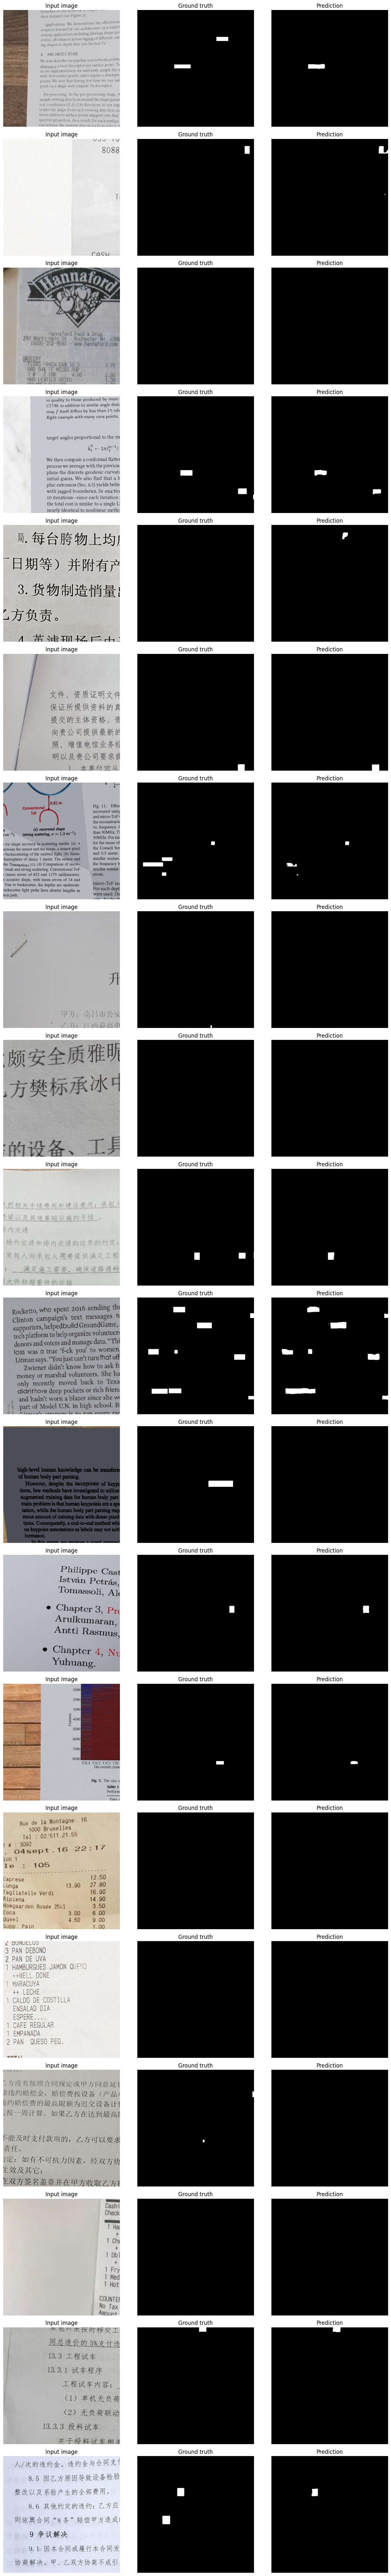

In [22]:
@torch.no_grad()
def visualize_predictions(model, dataset, device, num_samples=4, threshold=0.5):
    model.eval()

    if len(dataset) == 0:
        print("Dataset is empty.")
        return

    vis_rng = random.Random(SEED + 2)
    selected_indices = vis_rng.sample(
        range(len(dataset)),
        k=min(num_samples, len(dataset))
    )

    fig, axes = plt.subplots(
        len(selected_indices), 3,
        figsize=(13, 4 * len(selected_indices)),
        squeeze=False
    )

    for row, idx in enumerate(selected_indices):
        image, mask = dataset[idx]

        logits = model(image.unsqueeze(0).to(device))
        prediction = (
            torch.sigmoid(logits) >= threshold
        ).float().squeeze().cpu().numpy()

        # Undo ImageNet normalization for display only.
        mean = torch.tensor(MEAN).view(3, 1, 1)
        std = torch.tensor(STD).view(3, 1, 1)
        image_for_display = (image.cpu() * std + mean).clamp(0, 1)
        image_np = image_for_display.permute(1, 2, 0).numpy()
        mask_np = mask.squeeze().cpu().numpy()

        axes[row, 0].imshow(image_np)
        axes[row, 0].set_title("Input image")
        axes[row, 1].imshow(mask_np, cmap="gray", vmin=0, vmax=1)
        axes[row, 1].set_title("Ground truth")
        axes[row, 2].imshow(prediction, cmap="gray", vmin=0, vmax=1)
        axes[row, 2].set_title("Prediction")

        for ax in axes[row]:
            ax.axis("off")

    plt.tight_layout()
    plt.show()


visualize_predictions(model, test_dataset, device, num_samples=20)

# Block 8: VLM

In [39]:
import json
import warnings
from PIL import ImageDraw
from scipy import ndimage

# ----- Select one input image -----
VLM_INPUT_MODE = "lmdb"  # "lmdb" or "custom"
VLM_SPLIT_NAME = "DocTamperV1-TestingSet"
VLM_SAMPLE_INDEX = 2  # zero-based index in the selected LMDB split
VLM_CUSTOM_IMAGE_PATH = ""  # used only when VLM_INPUT_MODE == "custom"

# ----- Detector evidence settings -----
VLM_THRESHOLD = 0.50
VLM_MIN_REGION_AREA = 16
VLM_MAX_REGIONS = 2
VLM_REGION_PADDING_RATIO = 0.15
VLM_MAX_IMAGE_SIDE = None  # None keeps the original image size; e.g. 1024 reduces VRAM

# ----- VLM settings -----
VLM_MODEL_ID = "HuggingFaceTB/SmolVLM2-500M-Video-Instruct"
VLM_MAX_NEW_TOKENS = 240

# Save next to the existing working/checkpoint directory when possible.
if BEST_MODEL_PATH.parent.parent.exists():
    VLM_OUTPUT_DIR = BEST_MODEL_PATH.parent.parent / "vlm_outputs"
elif Path("/kaggle/working").exists():
    VLM_OUTPUT_DIR = Path("/kaggle/working/vlm_outputs")
else:
    VLM_OUTPUT_DIR = Path("./vlm_outputs")
VLM_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Detector device:", device)
print("Input mode:", VLM_INPUT_MODE)
print("Output directory:", VLM_OUTPUT_DIR)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))


Detector device: cuda
Input mode: lmdb
Output directory: /workspace/working/vlm_outputs
GPU: NVIDIA GeForce RTX 5070 Ti
GPU memory (GB): 15.46


Source: DocTamperV1-TestingSet / index=2
Original image size (W, H): (512, 512)


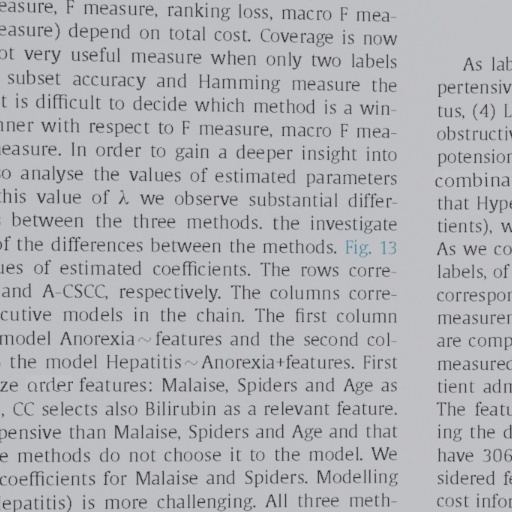

In [40]:
def load_vlm_input_image():
    if VLM_INPUT_MODE == "lmdb":
        if VLM_SPLIT_NAME not in envs:
            raise KeyError(
                f"Không tìm thấy split {VLM_SPLIT_NAME!r}. Các split hiện có: {list(envs.keys())}"
            )
        env = envs[VLM_SPLIT_NAME]
        n_samples = get_num_samples(env)
        if not (0 <= VLM_SAMPLE_INDEX < n_samples):
            raise IndexError(
                f"VLM_SAMPLE_INDEX={VLM_SAMPLE_INDEX} không hợp lệ; split có {n_samples} ảnh."
            )
        image_key = f"image-{VLM_SAMPLE_INDEX:09d}".encode("utf-8")
        with env.begin() as txn:
            image_buffer = txn.get(image_key)
        if image_buffer is None:
            raise KeyError(f"Không tìm thấy LMDB key: {image_key!r}")
        image = Image.open(BytesIO(image_buffer)).convert("RGB")
        source_description = f"{VLM_SPLIT_NAME} / index={VLM_SAMPLE_INDEX}"

    elif VLM_INPUT_MODE == "custom":
        custom_path = Path(VLM_CUSTOM_IMAGE_PATH)
        if not custom_path.is_file():
            raise FileNotFoundError(f"Không tìm thấy ảnh: {custom_path}")
        image = Image.open(custom_path).convert("RGB")
        source_description = str(custom_path)

    else:
        raise ValueError("VLM_INPUT_MODE phải là 'lmdb' hoặc 'custom'.")

    return image, source_description

original_image, VLM_INPUT_DESCRIPTION = load_vlm_input_image()
print("Source:", VLM_INPUT_DESCRIPTION)
print("Original image size (W, H):", original_image.size)
display(original_image)


In [41]:
def prepare_vlm_detector_tensor(image: Image.Image, max_side=None):
    work_image = image.convert("RGB")
    if max_side is not None:
        width, height = work_image.size
        scale = min(1.0, float(max_side) / max(width, height))
        if scale < 1.0:
            new_size = (max(1, round(width * scale)), max(1, round(height * scale)))
            work_image = work_image.resize(new_size, Image.Resampling.BILINEAR)

    image_array = np.asarray(work_image, dtype=np.float32) / 255.0
    tensor = torch.from_numpy(image_array).permute(2, 0, 1).contiguous()
    mean = torch.tensor(MEAN, dtype=tensor.dtype).view(3, 1, 1)
    std = torch.tensor(STD, dtype=tensor.dtype).view(3, 1, 1)
    tensor = ((tensor - mean) / std).unsqueeze(0)
    return tensor, work_image.size


@torch.inference_mode()
def predict_vlm_probability_map(detector, image: Image.Image, max_side=None):
    detector.eval()
    tensor, inference_size = prepare_vlm_detector_tensor(image, max_side=max_side)
    tensor = tensor.to(device, non_blocking=True)

    if device == "cuda":
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = detector(tensor)
    else:
        logits = detector(tensor)

    probability = torch.sigmoid(logits.float())[0, 0].cpu()
    original_width, original_height = image.size
    if inference_size != image.size:
        probability = F.interpolate(
            probability[None, None],
            size=(original_height, original_width),
            mode="bilinear",
            align_corners=False,
        )[0, 0]
    return probability.numpy().clip(0.0, 1.0)


def build_vlm_evidence(image: Image.Image, prob_map: np.ndarray):
    image = image.convert("RGB")
    image_array = np.asarray(image).copy()
    height, width = image_array.shape[:2]
    if prob_map.shape != (height, width):
        raise ValueError(f"Probability map {prob_map.shape} không khớp ảnh {(height, width)}")

    binary_mask = (prob_map >= VLM_THRESHOLD).astype(np.uint8)
    labels, number_of_components = ndimage.label(
        binary_mask, structure=np.ones((3, 3), dtype=np.uint8)
    )

    candidates = []
    component_slices = ndimage.find_objects(labels)
    for component_id, component_slice in enumerate(component_slices, start=1):
        if component_slice is None:
            continue
        y_slice, x_slice = component_slice
        component_mask = labels[component_slice] == component_id
        area = int(component_mask.sum())
        if area < VLM_MIN_REGION_AREA:
            continue
        x1, y1 = int(x_slice.start), int(y_slice.start)
        x2, y2 = int(x_slice.stop), int(y_slice.stop)
        component_probability = prob_map[component_slice][component_mask]
        candidates.append({
            "component_id": int(component_id),
            "area": area,
            "bbox_xyxy": [x1, y1, x2, y2],
            "mean_confidence": float(component_probability.mean()),
        })

    candidates.sort(key=lambda item: item["area"], reverse=True)
    selected_candidates = candidates[:VLM_MAX_REGIONS]

    # Overlay all components surviving the area filter; boxes identify selected crops.
    valid_ids = [item["component_id"] for item in candidates]
    valid_mask = np.isin(labels, valid_ids) if valid_ids else np.zeros_like(binary_mask, dtype=bool)
    overlay_array = image_array.copy()
    red = np.zeros_like(overlay_array)
    red[..., 0] = 255
    overlay_array[valid_mask] = (
        0.55 * overlay_array[valid_mask] + 0.45 * red[valid_mask]
    ).astype(np.uint8)
    overlay_image = Image.fromarray(overlay_array)
    draw = ImageDraw.Draw(overlay_image)

    regions = []
    for region_number, item in enumerate(selected_candidates, start=1):
        x1, y1, x2, y2 = item["bbox_xyxy"]
        pad_x = int((x2 - x1) * VLM_REGION_PADDING_RATIO)
        pad_y = int((y2 - y1) * VLM_REGION_PADDING_RATIO)
        px1, py1 = max(0, x1 - pad_x), max(0, y1 - pad_y)
        px2, py2 = min(width, x2 + pad_x), min(height, y2 + pad_y)
        draw.rectangle(
            (x1, y1, max(x1, x2 - 1), max(y1, y2 - 1)),
            outline=(255, 230, 0),
            width=max(2, width // 600),
        )
        draw.text((x1, max(0, y1 - 16)), f"R{region_number}", fill=(255, 230, 0))
        crop = image.crop((px1, py1, px2, py2))
        regions.append({
            "region_id": region_number,
            **item,
            "padded_bbox_xyxy": [px1, py1, px2, py2],
            "crop": crop,
        })

    return {
        "prob_map": prob_map,
        "binary_mask": binary_mask,
        "overlay": overlay_image,
        "regions": regions,
        "num_components_above_min_area": len(candidates),
    }


prob_map = predict_vlm_probability_map(
    model, original_image, max_side=VLM_MAX_IMAGE_SIDE
)
evidence = build_vlm_evidence(original_image, prob_map)

print("Threshold:", VLM_THRESHOLD)
print("Components above min area:", evidence["num_components_above_min_area"])
print("Regions sent to VLM:", len(evidence["regions"]))
print("Mean detector score:", round(float(prob_map.mean()), 4))


Threshold: 0.5
Components above min area: 3
Regions sent to VLM: 2
Mean detector score: 0.0106


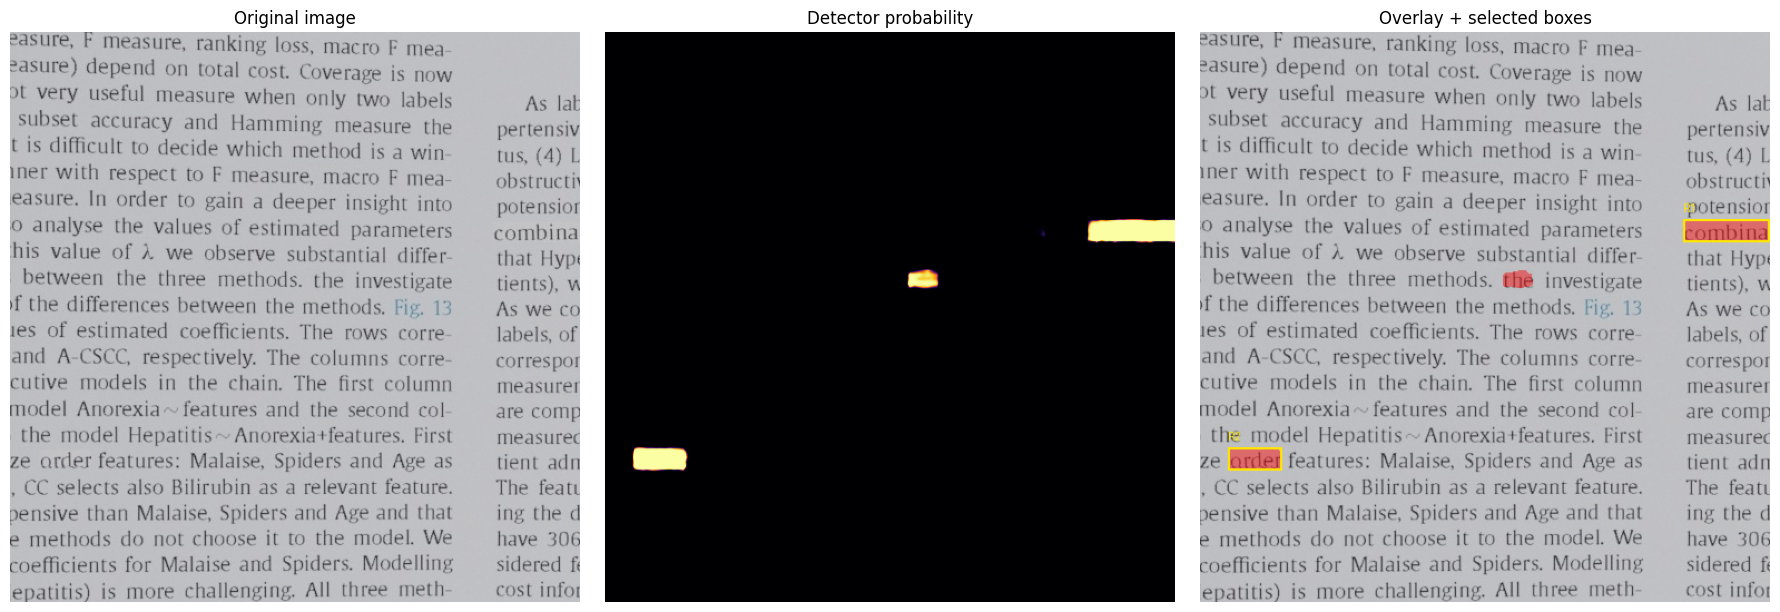

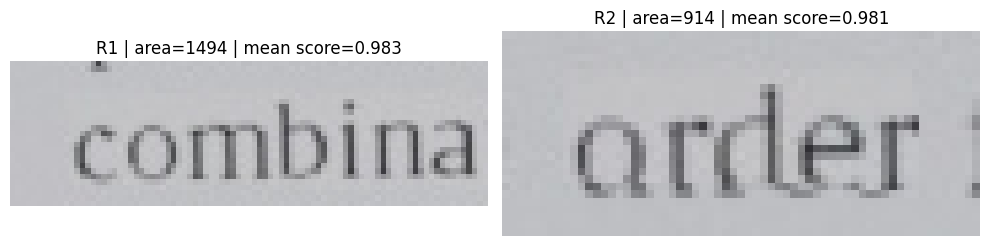

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(original_image)
axes[0].set_title("Original image")
axes[1].imshow(evidence["prob_map"], cmap="inferno", vmin=0, vmax=1)
axes[1].set_title("Detector probability")
axes[2].imshow(evidence["overlay"])
axes[2].set_title("Overlay + selected boxes")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

if evidence["regions"]:
    fig, axes = plt.subplots(
        1, len(evidence["regions"]),
        figsize=(5 * len(evidence["regions"]), 5),
        squeeze=False,
    )
    for ax, region in zip(axes[0], evidence["regions"]):
        ax.imshow(region["crop"])
        ax.set_title(
            f"R{region['region_id']} | area={region['area']} | "
            f"mean score={region['mean_confidence']:.3f}"
        )
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("Không có vùng nào vượt threshold và minimum-area hiện tại. VLM vẫn có thể xem ảnh gốc và overlay.")


In [43]:
%pip install -q -U "transformers>=4.57.0" accelerate num2words


Note: you may need to restart the kernel to use updated packages.


In [44]:
import transformers
from transformers import AutoProcessor

try:
    from transformers import AutoModelForImageTextToText as VLMModelClass
except ImportError:
    from transformers import AutoModelForMultimodalLM as VLMModelClass

print("Transformers version:", transformers.__version__)
print("VLM model:", VLM_MODEL_ID)

vlm_dtype = torch.float16 if torch.cuda.is_available() else torch.float32
processor = AutoProcessor.from_pretrained(VLM_MODEL_ID)

vlm_load_kwargs = {
    "torch_dtype": vlm_dtype,
    "low_cpu_mem_usage": True,
}
if torch.cuda.is_available():
    vlm_load_kwargs["device_map"] = "auto"

vlm = VLMModelClass.from_pretrained(VLM_MODEL_ID, **vlm_load_kwargs)
if not torch.cuda.is_available():
    vlm = vlm.to("cpu")
vlm.eval()
print("VLM device:", vlm.device)


Transformers version: 5.22.1
VLM model: HuggingFaceTB/SmolVLM2-500M-Video-Instruct


Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

VLM device: cuda:0


In [45]:
def save_vlm_image(image: Image.Image, path: Path):
    path.parent.mkdir(parents=True, exist_ok=True)
    image.convert("RGB").save(path, format="JPEG", quality=95)
    return path


def explain_document_with_vlm(
    original_image: Image.Image,
    evidence: dict,
    processor,
    vlm,
    output_dir: Path,
    max_new_tokens=240,
):
    input_dir = output_dir / "vlm_inputs"
    input_dir.mkdir(parents=True, exist_ok=True)

    original_path = save_vlm_image(original_image, input_dir / "original.jpg")
    overlay_path = save_vlm_image(evidence["overlay"], input_dir / "detector_overlay.jpg")

    region_metadata = []
    content = [
        {"type": "text", "text": "Ảnh 1 là ảnh tài liệu gốc. Dùng ảnh này để hiểu nội dung và bố cục."},
        {"type": "image", "path": str(original_path)},
        {"type": "text", "text": "Ảnh 2 là overlay từ detector. Màu đỏ biểu thị các vùng mask vượt bộ lọc diện tích; khung vàng đánh dấu các crop được chọn. Đây chỉ là dự đoán của detector."},
        {"type": "image", "path": str(overlay_path)},
    ]

    for region in evidence["regions"]:
        crop_path = save_vlm_image(
            region["crop"], input_dir / f"region_{region['region_id']}.jpg"
        )
        region_metadata.append({
            "region_id": int(region["region_id"]),
            "bbox_xyxy": [int(v) for v in region["bbox_xyxy"]],
            "padded_bbox_xyxy": [int(v) for v in region["padded_bbox_xyxy"]],
            "area_pixels": int(region["area"]),
            "mean_detector_score": round(float(region["mean_confidence"]), 4),
        })
        content.extend([
            {"type": "text", "text": f"Ảnh crop của vùng nghi vấn R{region['region_id']}."},
            {"type": "image", "path": str(crop_path)},
        ])

    metadata = {
        "threshold": float(VLM_THRESHOLD),
        "num_components_above_min_area": int(evidence["num_components_above_min_area"]),
        "num_regions_sent": len(region_metadata),
        "regions": region_metadata,
        "warning": (
            "Detector score is not a calibrated probability that tampering occurred."
        ),
    }

    prompt = f"""
Bạn là mô-đun giải thích bằng chứng cho hệ thống phát hiện vùng chữ nghi vấn trong ảnh tài liệu.

THÔNG TIN DETECTOR (JSON):
{json.dumps(metadata, ensure_ascii=False, indent=2)}

NHIỆM VỤ:
1. Tóm tắt ngắn gọn những vùng detector đã đánh dấu.
2. Với từng vùng R1, R2..., mô tả chữ hoặc thành phần tài liệu nhìn thấy được. Chỉ chép lại chữ nếu thực sự đọc rõ.
3. Nêu đặc điểm thị giác có thể quan sát trực tiếp trong crop và khi so với vùng xung quanh, chẳng hạn độ đậm nét, căn chỉnh, nền, khoảng cách hoặc ranh giới. Không tự tạo dấu hiệu.
4. Nêu rõ điều gì chưa thể kết luận từ ảnh.

QUY TẮC:
- Vùng màu đỏ chỉ là dự đoán của detector, KHÔNG đồng nghĩa chắc chắn đã bị giả mạo.
- Không suy đoán nội dung ban đầu, nội dung bị thay thế, người chỉnh sửa hoặc phần mềm đã dùng.
- Không khẳng định có chỉnh sửa chỉ dựa vào detector score.
- Nếu chữ nhỏ, mờ hoặc khó đọc, nói rõ là không đọc chắc chắn.
- Nếu không có vùng nào vượt ngưỡng, nói rõ detector không tạo ra vùng ứng viên theo ngưỡng hiện tại; không kết luận tài liệu chắc chắn nguyên vẹn.
- Phân biệt điều quan sát được và điều chưa thể kết luận.
- Trả lời bằng tiếng Việt.

ĐỊNH DẠNG:
A. Tóm tắt
B. Phân tích từng vùng
C. Bằng chứng quan sát được
D. Giới hạn kết luận
E. Đánh giá tổng quát: Có vùng nghi vấn / Chưa đủ bằng chứng
"""
    content.append({"type": "text", "text": prompt})

    messages = [{"role": "user", "content": content}]
    inputs = processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt",
    ).to(vlm.device, dtype=vlm_dtype)

    with torch.inference_mode():
        generated_ids = vlm.generate(
            **inputs,
            do_sample=False,
            max_new_tokens=max_new_tokens,
        )

    prompt_length = inputs["input_ids"].shape[-1]
    generated_only = generated_ids[:, prompt_length:]
    explanation = processor.batch_decode(
        generated_only, skip_special_tokens=True
    )[0].strip()
    return explanation, metadata


explanation, explanation_metadata = explain_document_with_vlm(
    original_image=original_image,
    evidence=evidence,
    processor=processor,
    vlm=vlm,
    output_dir=VLM_OUTPUT_DIR,
    max_new_tokens=VLM_MAX_NEW_TOKENS,
)

print(explanation)


Định dạng:
A. Tóm tắt
B. Phân tích từng vùng
C. Bằng chứng quan sát được
D. Giới hạn kết luận
E. Đánh giá tổng quát: Có vùng nghi vấn / Chưa đủ bằng chứng


In [46]:
report_path = VLM_OUTPUT_DIR / "explanation_report.txt"
metadata_path = VLM_OUTPUT_DIR / "evidence_metadata.json"

report_text = (
    "DocTamper VLM MVP Report\n"
    "========================\n\n"
    + f"Input: {VLM_INPUT_DESCRIPTION}\n"
    + f"Threshold: {VLM_THRESHOLD}\n"
    + f"Components above minimum area: {evidence['num_components_above_min_area']}\n"
    + f"Regions sent to VLM: {len(evidence['regions'])}\n\n"
    + explanation
)
report_path.write_text(report_text, encoding="utf-8")
metadata_path.write_text(
    json.dumps(explanation_metadata, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

original_image.save(VLM_OUTPUT_DIR / "original.png")
evidence["overlay"].save(VLM_OUTPUT_DIR / "detector_overlay.png")
Image.fromarray((evidence["prob_map"] * 255).astype(np.uint8)).save(
    VLM_OUTPUT_DIR / "probability_map.png"
)
Image.fromarray((evidence["binary_mask"] * 255).astype(np.uint8)).save(
    VLM_OUTPUT_DIR / "binary_mask.png"
)

print("Saved report:", report_path)
print("Saved metadata:", metadata_path)
print("Saved overlay:", VLM_OUTPUT_DIR / "detector_overlay.png")
print("Saved probability map:", VLM_OUTPUT_DIR / "probability_map.png")


Saved report: /workspace/working/vlm_outputs/explanation_report.txt
Saved metadata: /workspace/working/vlm_outputs/evidence_metadata.json
Saved overlay: /workspace/working/vlm_outputs/detector_overlay.png
Saved probability map: /workspace/working/vlm_outputs/probability_map.png
